In [1]:
!pip install yahoo_fin

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.1/81.1 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.4/83.4 kB 6.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 9.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.8/106.8 kB 13.9 MB/s eta 0:00:00
  Created wheel for bs4: filename=bs4-0.0.1-py3-none-any.whl size=1256 sha256=86d84deb78a086e6a2e6c016d6f3b9adb7e119c38dc132dd0576656262d58b13
  Stored in directory: /root/.cache/pip/wheels/25/42/45/b773edc52acb16cd2db4cf1a0b47117e2f69bb4eb300ed0e70
  Created wheel for sgmllib3k: filename=sgmllib3k-1.0.0-py3-none-any.whl size=6048 sha256=d9385b6fbfe92dba4b38b4d4b1e1e94879338f947a81a75a64d64f2ef19eaaa6
  Stored in directory: /root/.cache/pip/wheels/f0/69/93/a47e9d621be168e9e33c7ce60524393c0b92ae83cf6c6e89c5
Successfully built bs4 sgmllib3k
  Attempting uninstall: urllib3
    Found existi

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
import seaborn as sns
import os
from datetime import datetime
from yahoo_fin import stock_info as yf
import time
import datetime as dt
import warnings
warnings.filterwarnings("ignore")


## 1. Downloading daily stocks prices

In [3]:

# Stock ticker, GOOGL
STOCK = 'GOOGL'

# Current date
date_now = time.strftime('%Y-%m-%d')
date_10_years_back = (dt.date.today() - dt.timedelta(days=(10*365))).strftime('%Y-%m-%d') #Stocks over last 10 years



In [4]:
data = yf.get_data(
    STOCK,
    start_date=date_10_years_back,
    end_date=date_now,
    interval='1d')
data=data.reset_index()
data.rename(columns={'index':'date'},inplace=True)
data.head()

,date,open,high,low,close,adjclose,volume,ticker
0,2013-12-05,26.456455,26.518019,26.303555,26.459961,26.459961,45302652,GOOGL
1,2013-12-06,26.771523,26.776777,26.528528,26.773523,26.773523,57094848,GOOGL
2,2013-12-09,26.801552,27.084835,26.727226,26.980480,26.980480,59244696,GOOGL
3,2013-12-10,26.930681,27.335085,26.918167,27.143644,27.143644,74081844,GOOGL
4,2013-12-11,27.212212,27.310310,26.906157,26.959209,26.959209,68403528,GOOGL


## Data Exploration and Visualisation

In [5]:

data['date'] = pd.to_datetime(data['date']) # converting date column to date time
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2515 entries, 0 to 2514
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      2515 non-null   datetime64[ns]
 1   open      2515 non-null   float64       
 2   high      2515 non-null   float64       
 3   low       2515 non-null   float64       
 4   close     2515 non-null   float64       
 5   adjclose  2515 non-null   float64       
 6   volume    2515 non-null   int64         
 7   ticker    2515 non-null   object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 157.3+ KB


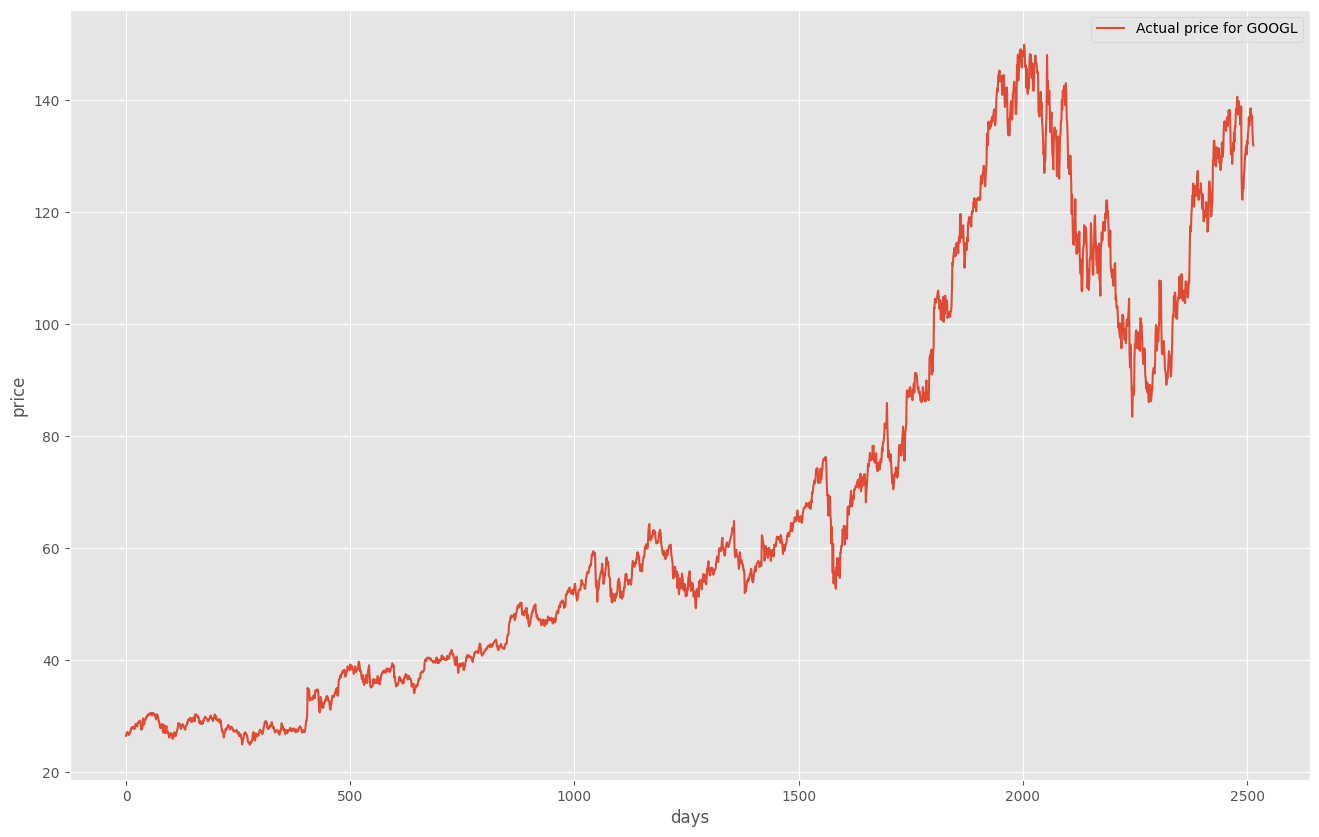

In [6]:
plt.style.use(style='ggplot')
plt.figure(figsize=(16,10))
plt.plot(data['close'])
plt.xlabel("days")
plt.ylabel("price")
plt.legend([f'Actual price for {STOCK}'])
plt.show()

## 2. Data Preperation

In [7]:
# Extract the 'close' column from the 'data' DataFrame
close_data = data.filter(['close'])

# Convert the 'close' column to a NumPy array
dataset = close_data.values

# Calculate the training size as 85% of the dataset length
training = int(np.ceil(len(dataset) * .85))
# Print the training size
print(training)


2138


In [8]:
from sklearn.preprocessing import MinMaxScaler

# Create a MinMaxScaler object with a feature range of (0, 1)
scaler = MinMaxScaler(feature_range=(0, 1))

# Use the scaler to transform the 'dataset' values to a scaled version
scaled_data = scaler.fit_transform(dataset)

# Select the training data by slicing the 'scaled_data' array
train_data = scaled_data[0:int(training), :]


### Splitting Data

In [9]:
def generate_train_data(window_size):
    # Prepare features and labels
    x_train = []  # List to store input sequences
    y_train = []  # List to store corresponding labels

    # Iterate through the training data
    for i in range(window_size, len(train_data)):
        # Create input sequence by slicing the 'train_data' array
        x_train.append(train_data[i - window_size:i, 0])

        # Create corresponding label by selecting the next value in 'train_data'
        y_train.append(train_data[i, 0])

    # Convert lists to NumPy arrays
    x_train, y_train = np.array(x_train), np.array(y_train)

    # Reshape the input data to fit the LSTM model requirements
    x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

    return x_train, y_train  # Return the prepared training data


In [10]:
x_train,y_train = generate_train_data(50)


## 3/4. Model Architecture and Training

In [11]:
# Create a Sequential model using Keras
model = keras.models.Sequential()

# Add an LSTM layer with 64 units, returning sequences, and specifying input shape
model.add(keras.layers.LSTM(units=64,
                            return_sequences=True,
                            input_shape=(x_train.shape[1], 1)))

# Add another LSTM layer with 64 units
model.add(keras.layers.LSTM(units=64))

# Add a Dense layer with 32 units
model.add(keras.layers.Dense(32))

# Add a Dropout layer with a dropout rate of 0.5
model.add(keras.layers.Dropout(0.5))

# Add a Dense layer with 1 unit (output layer)
model.add(keras.layers.Dense(1))

# Display a summary of the model architecture
model.summary()



Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 50, 64)            16896     
                                                                 
 lstm_1 (LSTM)               (None, 64)                33024     
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 52033 (203.25 KB)
Trainable params: 52033 (203.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [12]:
# Compile the model with the Adam optimizer and mean squared error loss
model.compile(optimizer='adam',
			loss='mean_squared_error')
# Train the model on the provided training data
history = model.fit(x_train,
					y_train,
                    batch_size=32,
					epochs=50)

Epoch 1/50
66/66 [==============================] - 18s 16ms/step - loss: 0.0220
Epoch 2/50
66/66 [==============================] - 1s 14ms/step - loss: 0.0077
Epoch 3/50
66/66 [==============================] - 1s 10ms/step - loss: 0.0066
Epoch 4/50
66/66 [==============================] - 1s 9ms/step - loss: 0.0047
Epoch 5/50
66/66 [==============================] - 1s 13ms/step - loss: 0.0047
Epoch 6/50
66/66 [==============================] - 1s 8ms/step - loss: 0.0049
Epoch 7/50
66/66 [==============================] - 1s 8ms/step - loss: 0.0049
Epoch 8/50
66/66 [==============================] - 1s 9ms/step - loss: 0.0041
Epoch 9/50
66/66 [==============================] - 1s 8ms/step - loss: 0.0041
Epoch 10/50
66/66 [==============================] - 1s 11ms/step - loss: 0.0043
Epoch 11/50
66/66 [==============================] - 1s 13ms/step - loss: 0.0036
Epoch 12/50
66/66 [==============================] - 1s 14ms/step - loss: 0.0043
Epoch 13/50
66/66 [======================

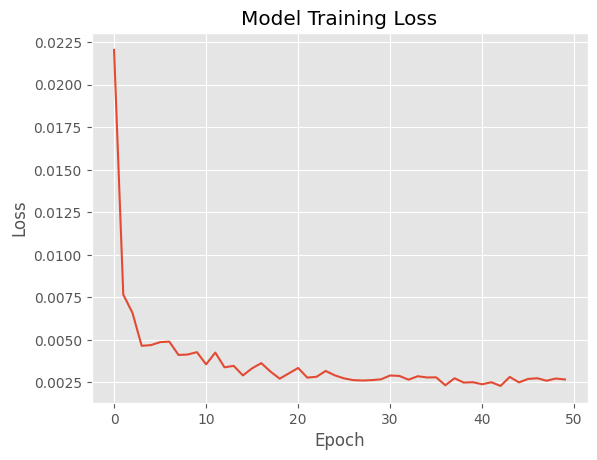

In [13]:
plt.plot(history.history['loss'])
plt.title('Model Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

## Splitting Test data

In [14]:
def generate_test_data(window_size):
    # Extract test data from the scaled data, starting from the training index
    test_data = scaled_data[training - window_size:, :]

    # Initialize lists to store input sequences and corresponding labels
    x_test = []  # List to store input sequences
    y_test = dataset[training:, :]  # Labels for the test data

    # Iterate through the test data
    for i in range(window_size, len(test_data)):
        # Create input sequence by slicing the 'test_data' array
        x_test.append(test_data[i - window_size:i, 0])

    # Convert the list of input sequences to a NumPy array
    x_test = np.array(x_test)

    # Reshape the input test data to fit the LSTM model requirements
    x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

    return x_test, y_test

## 5. Model Evaluation

In [30]:
def evaluate_predictions(model, x_test, y_test, training_data,window):
    predictions = []
    prediction_transformed=[]

    # Initialize with the last 50 data points from the training set
    current_input = y_train[-window:]

    # Iterate through the test data
    for i in range(len(x_test)):

        prediction = model.predict(np.array([current_input]))
        prediction_transform = scaler.inverse_transform(prediction)[0][0]
        print(prediction[0][0])

        # Store the prediction
        predictions.append(prediction)

        prediction_transformed.append(prediction_transform)
        # Update the current input for the next iteration
        current_input = np.concatenate([current_input[1:], ([prediction][0][0])])

    # Convert predictions to a NumPy array
    # predictions = np.array(predictions)
    prediction_transformed =np.array(prediction_transformed)



    # Evaluate the performance
    mse = np.mean((predictions - y_test[:, 0])**2)
    rmse = np.sqrt(mse)

    return prediction_transformed, mse, rmse

window=50
x_test, y_test = generate_test_data(window)
predictions, mse_50, rmse_50 = evaluate_predictions(model, x_test, y_test, train_data[:, 0],window)



print("MSE:", mse_50)
print("RMSE:", rmse_50)


1/1 [==============================] - 0s 30ms/step
0.6868991
1/1 [==============================] - 0s 48ms/step
0.6898399
1/1 [==============================] - 0s 58ms/step
0.6902117
1/1 [==============================] - 0s 128ms/step
0.68957984
1/1 [==============================] - 0s 101ms/step
0.6885242
1/1 [==============================] - 0s 74ms/step
0.687272
1/1 [==============================] - 0s 54ms/step
0.6859208
1/1 [==============================] - 0s 21ms/step
0.68451804
1/1 [==============================] - 0s 18ms/step
0.6830904
1/1 [==============================] - 0s 18ms/step
0.6816539
1/1 [==============================] - 0s 18ms/step
0.68021923
1/1 [==============================] - 0s 21ms/step
0.6787932
1/1 [==============================] - 0s 27ms/step
0.67738
1/1 [==============================] - 0s 20ms/step
0.67598253
1/1 [==============================] - 0s 20ms/step
0.6746019
1/1 [==============================] - 0s 19ms/step
0.6732389
1/1 [

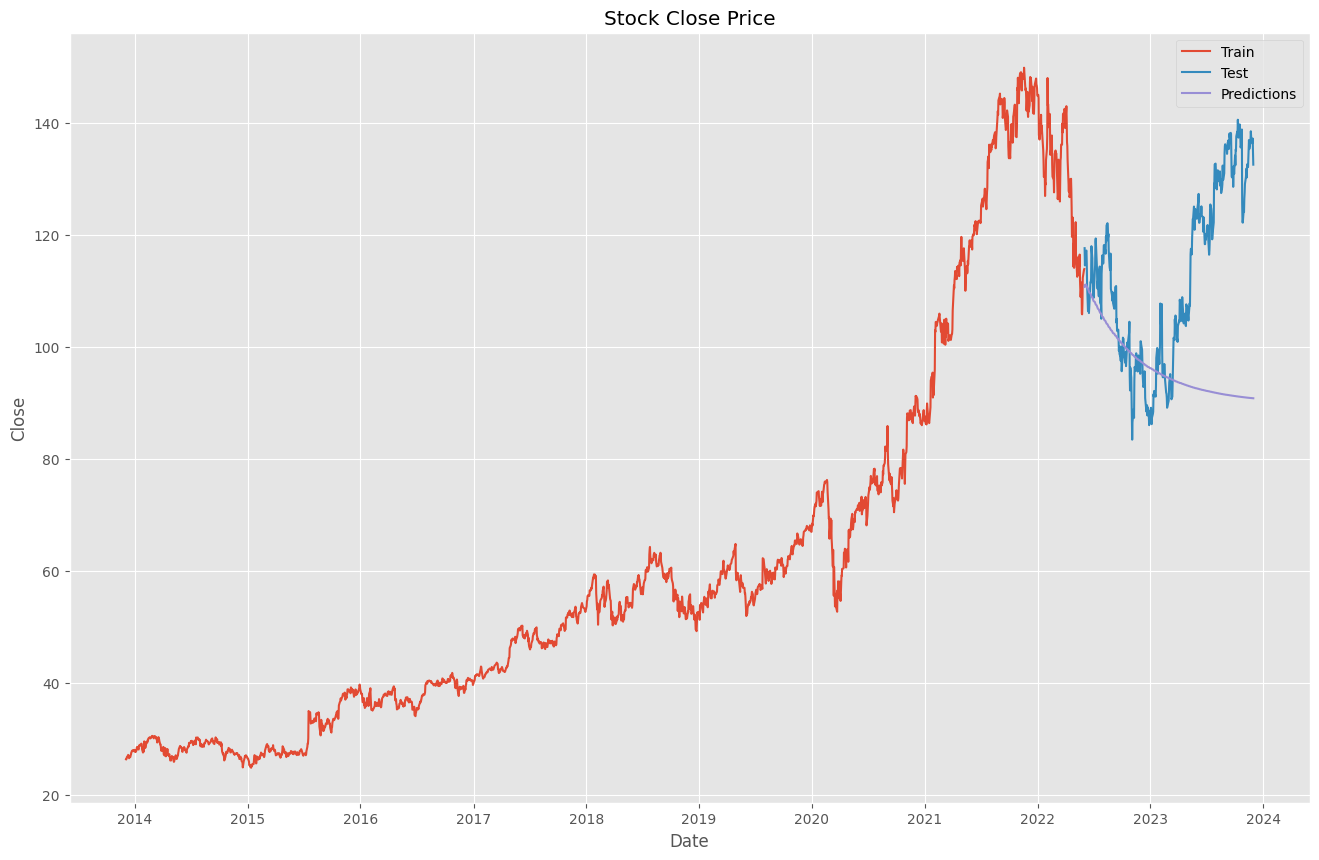

In [22]:
train = data[:training]
test = data[training:]

# Create DataFrame for predictions
test_predictions_df = pd.DataFrame({'date': test['date'], 'Predictions': predictions.reshape(-1)})

# Plotting
plt.style.use(style='ggplot')
plt.figure(figsize=(16, 10))

# Plot the training data
plt.plot(train['date'].to_numpy(), train['close'].to_numpy(), label='Train')

# Plot the test data
plt.plot(test['date'].to_numpy(), test['close'].to_numpy(), label='Test')

# Plot the predictions
plt.plot(test_predictions_df['date'].to_numpy(), test_predictions_df['Predictions'].to_numpy(), label='Predictions')

plt.title('Stock Close Price')
plt.xlabel('Date')
plt.ylabel('Close')
plt.legend()

plt.show()


## 6. Training Models with different sliding windows

In [26]:
def create_models(windows_list):

    results_df = pd.DataFrame(columns=['Window', 'MSE', 'RMSE'])

    for i in windows_list:
        x_train,y_train = generate_train_data(i)
        x_test,y_test=generate_test_data(i)
        model = keras.models.Sequential()
        model.add(keras.layers.LSTM(units=64,
                                    return_sequences=True,
                                    input_shape=(x_train.shape[1], 1)))
        model.add(keras.layers.LSTM(units=64))
        model.add(keras.layers.Dense(32))
        model.add(keras.layers.Dropout(0.5))
        model.add(keras.layers.Dense(1))
        model.summary()
        model.compile(optimizer='adam',
                loss='mean_squared_error')
        history = model.fit(x_train,
                        y_train,
                        batch_size=32,
                        epochs=50)
        # predict the testing data
        predictions, mse, rmse = evaluate_predictions(model, x_test, y_test, train_data[:, 0],i)

        train = data[:training]
        test = data[training:]

        # Create DataFrame for predictions
        test_predictions_df = pd.DataFrame({'date': test['date'], 'Predictions': predictions.reshape(-1)})

        # Plotting
        plt.style.use(style='ggplot')
        plt.figure(figsize=(16, 10))

        # Plot the training data
        plt.plot(train['date'].to_numpy(), train['close'].to_numpy(), label='Train')

        # Plot the test data
        plt.plot(test['date'].to_numpy(), test['close'].to_numpy(), label='Test')

        # Plot the predictions
        plt.plot(test_predictions_df['date'].to_numpy(), test_predictions_df['Predictions'].to_numpy(), label='Predictions')

        plt.title('Stock Close Price')
        plt.xlabel('Date')
        plt.ylabel('Close')
        plt.legend()

        plt.show()
        # Append results to the DataFrame
        results_df = results_df._append({'Window': i, 'MSE': mse, 'RMSE': rmse}, ignore_index=True)
    return results_df

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_4 (LSTM)               (None, 10, 64)            16896     
                                                                 
 lstm_5 (LSTM)               (None, 64)                33024     
                                                                 
 dense_4 (Dense)             (None, 32)                2080      
                                                                 
 dropout_2 (Dropout)         (None, 32)                0         
                                                                 
 dense_5 (Dense)             (None, 1)                 33        
                                                                 
Total params: 52033 (203.25 KB)
Trainable params: 52033 (203.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/50
67/67

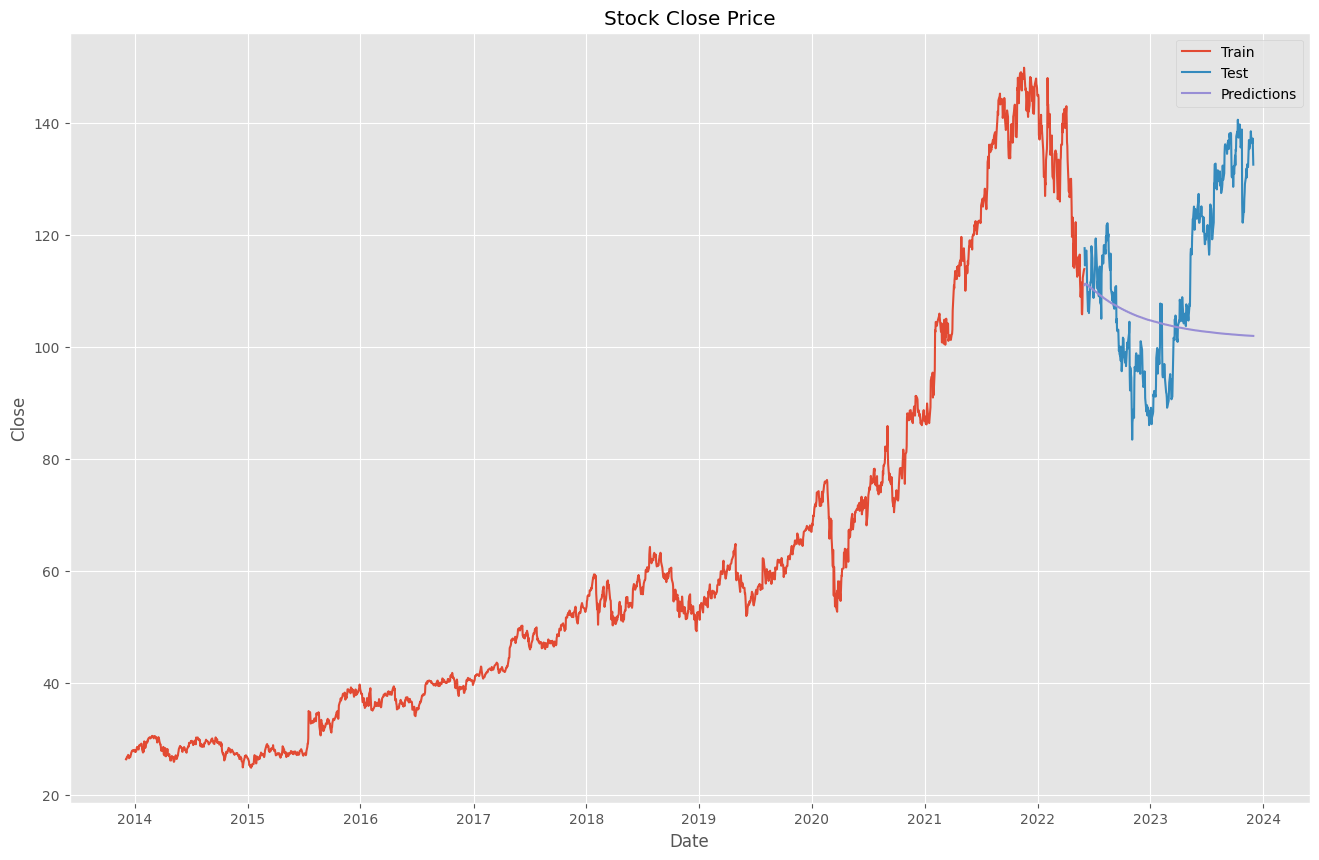

Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 25, 64)            16896     
                                                                 
 lstm_7 (LSTM)               (None, 64)                33024     
                                                                 
 dense_6 (Dense)             (None, 32)                2080      
                                                                 
 dropout_3 (Dropout)         (None, 32)                0         
                                                                 
 dense_7 (Dense)             (None, 1)                 33        
                                                                 
Total params: 52033 (203.25 KB)
Trainable params: 52033 (203.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/50
67/67

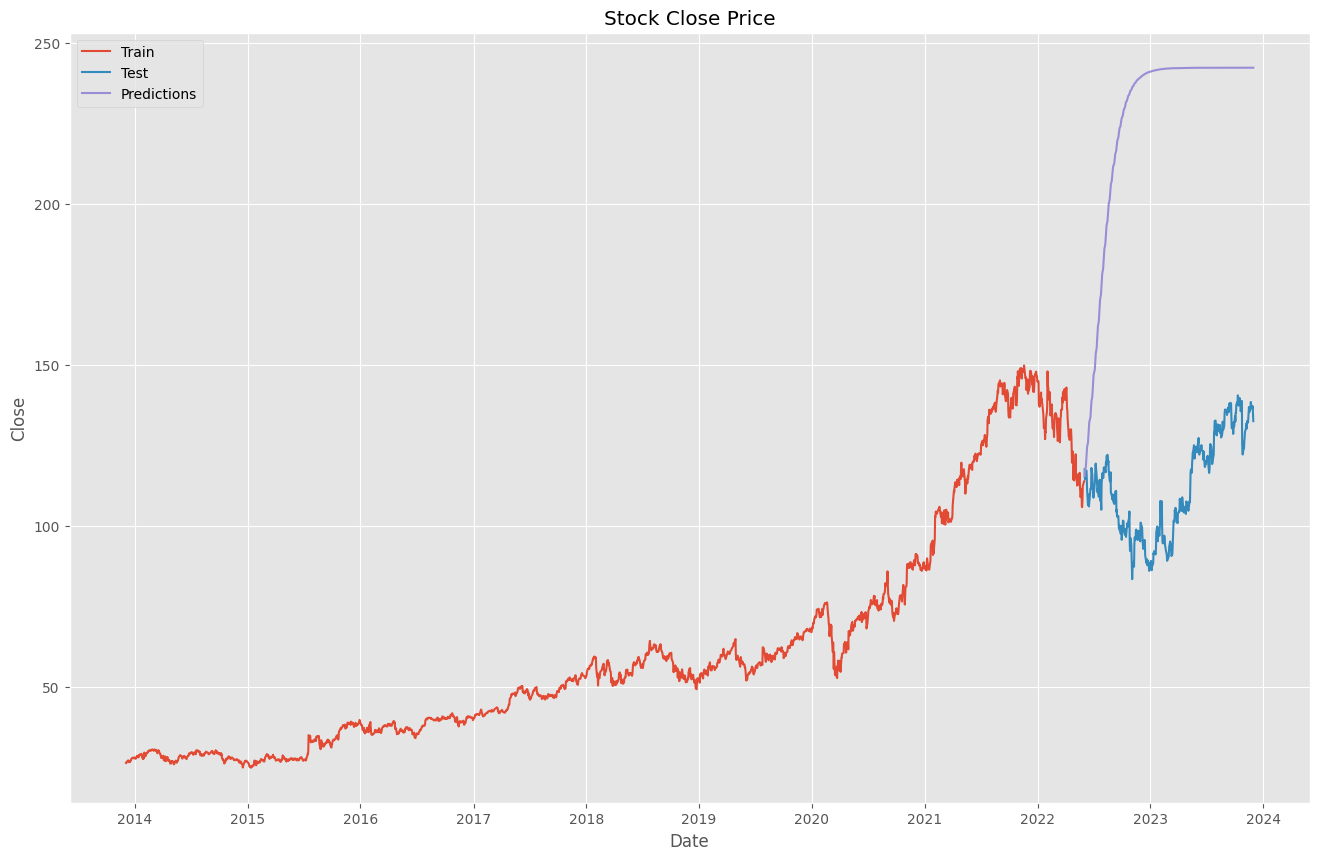

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_8 (LSTM)               (None, 100, 64)           16896     
                                                                 
 lstm_9 (LSTM)               (None, 64)                33024     
                                                                 
 dense_8 (Dense)             (None, 32)                2080      
                                                                 
 dropout_4 (Dropout)         (None, 32)                0         
                                                                 
 dense_9 (Dense)             (None, 1)                 33        
                                                                 
Total params: 52033 (203.25 KB)
Trainable params: 52033 (203.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________
Epoch 1/50
64/64

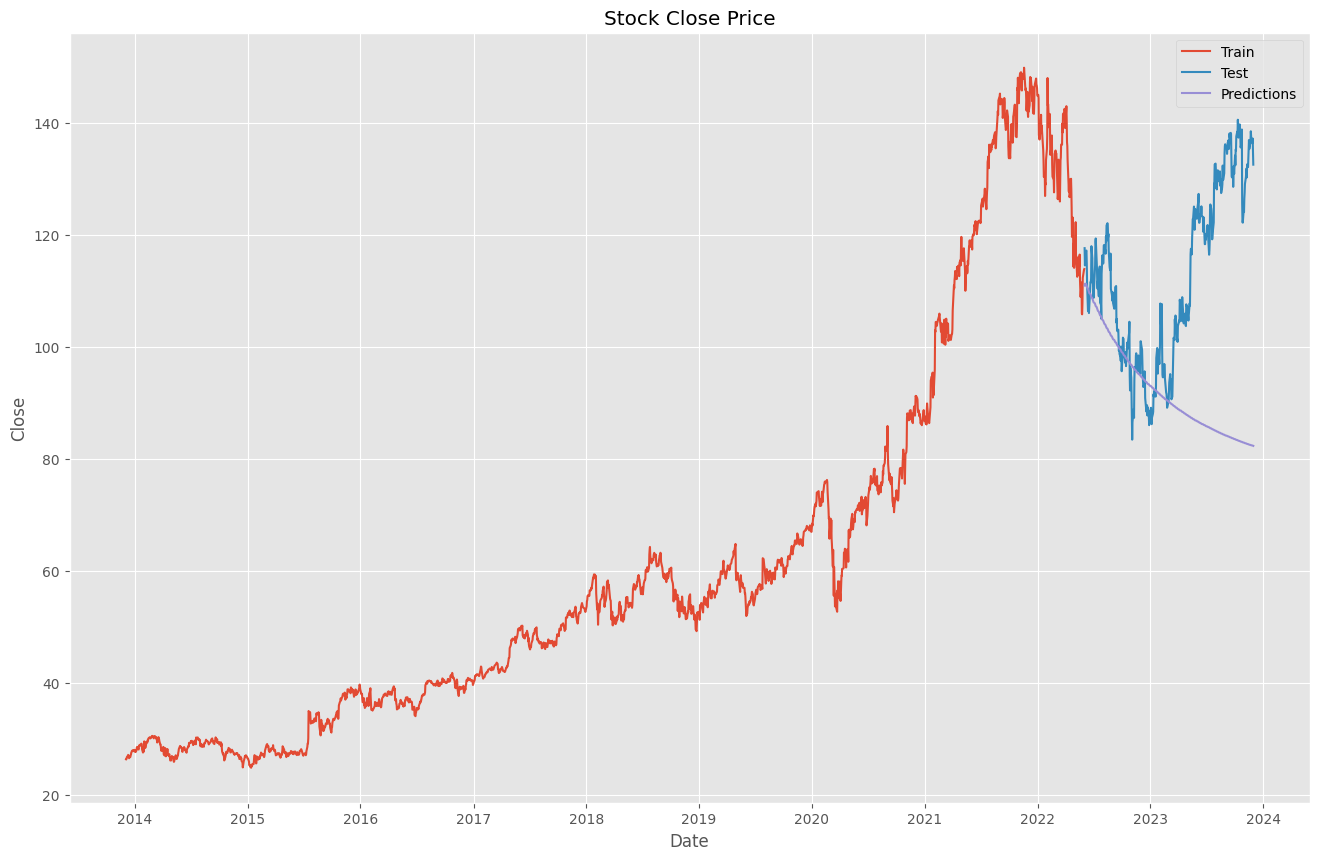

,Window,MSE,RMSE
0,10.0,12691.306463,112.655699
1,25.0,12473.953894,111.686856
2,100.0,12713.618361,112.754682


In [27]:
result= create_models([10, 25, 100])
result

In [28]:

def plot_model_comparison(results_df):
    plt.figure(figsize=(12, 6))

    # Bar plot for MSE
    plt.bar(results_df['Window'].to_numpy(), results_df['MSE'].to_numpy(), color='blue')
    plt.title('Mean Squared Error (MSE) Comparison')
    plt.xlabel('Window Size')
    plt.ylabel('MSE')
    plt.tight_layout()
    plt.show()



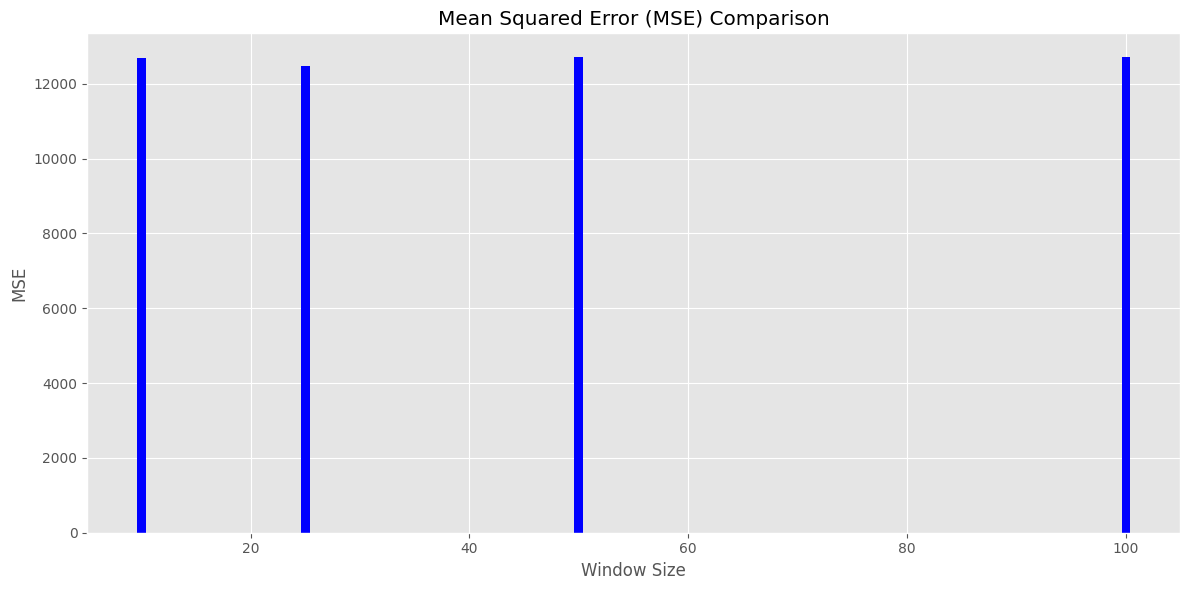

In [31]:
result=result._append({'Window': 50, 'MSE': mse_50, 'RMSE': rmse_50},ignore_index=True)
plot_model_comparison(result)

## 7. Discuss

### Strengts
1. A high window size of 100 seems to be more accurate than lower ones which makes sense, since the model has more data do base its desicion on.
2. And if we only were to predict the values for the next half year, the MSE would likely be lower.

### Weaknesses
1. Results may not be as good when the trend of the stock actually changes within the next weeks. Especially rare events that never happend before like the coronavirus disease will be challenging
2. It predicts well when the general direction the stock will go is the same as the one it has been before. Therefore, this bot is not useful since one can just assume that the stock will rise or fall at the same rate it has been for months until a rare event happens which cannot be predicted by this bot.

### Improvements
1. Train the model on the data of more stocks and not just one. But not all of them. Maybe only of the same Industry. For example tech or cryptocurrencies.
2. Not only provide the last 50 days of the stock value to predict the next day, also provide the last 50 days of an Index like S&P 500 to get the general direction of the market
3. Additionally provide the model with the sentiment of current news media about the company
4. Make the model predict the price in a week because the price for the next day might not change significantly most of the times.